# GLMs en la práctica: dos problemas que parecían otra cosa

**Estadística para IA, Concentración en IA, Tec de Monterrey**
Tutorial guiado del bloque de GLMs bayesianos (noviembre 2026)


En clase vimos el esqueleto de un modelo lineal generalizado: una **familia** para $y$, un **predictor lineal** y una **liga** que los conecta. Este notebook tiene un propósito distinto al de una tarea de repaso. La idea es que lo recorran con calma, corran cada celda, cambien cosas, y salgan con dos convicciones:

1. Varios problemas que a primera vista parecen exigir un método especial (toxicología, cuántas tiendas tienen hueco de distribución, cuánto vale una oportunidad comercial) se resuelven con **una versión de regresión**, bien pensada.
2. Lo difícil casi nunca está en el código. Está en decidir **qué estamos modelando** y en revisar si el modelo se parece a los datos.

Hay dos escenarios:

| Parte | Escenario | Qué se aprende |
|---|---|---|
| 1 | **Bioassay** (Gelman et al., BDA3, 3.7): ¿qué dosis de un compuesto mata a la mitad de los animales? | regresión binomial (no Bernoulli), la liga como modelo de una tolerancia latente, cantidades de interés que son funciones de los coeficientes, sensibilidad a la liga |
| 2 | **Arca (datos inventados)**: ¿una tienda vende cero de un energético porque no hay demanda, o porque el producto nunca llegó? | conteos con exposición, sobredispersión, ceros inflados, cómo un modelo mal especificado inventa efectos, y cómo pasar de coeficientes a una lista priorizada para el vendedor |

No vamos a poner el foco en los priors. Usaremos priors razonables y sencillos, y les diré por qué en una línea; ustedes ya saben juzgarlos con la predictiva previa.

**Cómo usarlo.** Corran las celdas en orden. Donde vean **Para pensar**, deténganse antes de seguir: la respuesta suele estar dos celdas abajo, y vale más si la intentan primero. Al final de cada parte hay una sección **Prueba tú** con extensiones opcionales.

## Antes de empezar: anatomía de un modelo en PyMC

Toda regresión contesta tres preguntas, y cada una corresponde a una línea de código en PyMC:

| Pregunta | En el modelo | En PyMC |
|---|---|---|
| 1. ¿Qué distribución tiene $y$ si conociera todo lo relevante del caso? | la **familia** | `pm.Binomial(..., observed=y)`, `pm.Poisson(...)`, etc. |
| 2. ¿Cómo depende la media de $y$ de las $x$? | **predictor lineal + liga** | una expresión como `pm.math.invlogit(a + b * x)` |
| 3. ¿Qué creo de los coeficientes antes de ver los datos? | el **prior** | `pm.Normal("b", 0, 1)` |

Y cuatro piezas más que van a usar todo el tiempo:

- `with pm.Model() as m:` abre un contexto; todo lo que se declara adentro pertenece a ese modelo.
- `observed=...` es lo que convierte una distribución en **verosimilitud**: le dice a PyMC "esta variable ya la vi, y vale esto".
- `pm.Deterministic("nombre", expresion)` guarda en el posterior cualquier función de los parámetros, para no tener que recalcularla.
- `pm.sample(...)` corre NUTS y regresa un objeto `InferenceData` con las muestras; `pm.sample_posterior_predictive(...)` simula datos nuevos con esas muestras.

Si no tienen PyMC instalado: `pip install pymc` (instala también ArviZ). El notebook está escrito para PyMC 5.

In [8]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import pymc as pm
import arviz as az
from scipy.special import expit, logit
from scipy.stats import norm

print("PyMC", pm.__version__, "| ArviZ", az.__version__)

SEMILLA = 2026
plt.rcParams.update({"figure.figsize": (7, 4), "axes.spines.top": False,
                     "axes.spines.right": False, "font.size": 10})


def muestras(idata, var, grupo="posterior"):
    # Regresa las muestras de `var` como arreglo de numpy, juntando todas las cadenas.
    # Forma: (n_muestras,) para un escalar; (n_muestras, ...) para un vector.
    v = np.asarray(getattr(idata, grupo)[var])
    return v.reshape(-1, *v.shape[2:])


def resumen(v, nombre=""):
    # Mediana e intervalo central del 95% de un vector de muestras.
    q = np.percentile(v, [2.5, 50, 97.5])
    print(f"{nombre:>34s}: {q[1]:9.3f}   [{q[0]:9.3f}, {q[2]:9.3f}]")

PyMC 5.28.5 | ArviZ 0.23.4



# Parte 1. Bioassay: qué dosis mata a la mitad?

## 1.1 Situación

En el desarrollo de un fármaco o de un químico, uno de los primeros experimentos es de toxicidad aguda. Se preparan varias dosis de un compuesto, a cada dosis se le asigna un grupo de animales, y se cuenta cuántos mueren. Los datos que usan Gelman et al. (BDA3, §3.7, tomados de Racine et al., 1986) son estos:

| dosis, $x_i$ (log g/ml) | animales, $n_i$ | muertes, $y_i$ |
|---|---|---|
| $-0.86$ | 5 | 0 |
| $-0.30$ | 5 | 1 |
| $-0.05$ | 5 | 3 |
| $0.73$ | 5 | 5 |

Veinte animales en total. La pregunta que le importa a un toxicólogo rara vez es "¿cuánto vale el coeficiente?", sino que más bien es:

> **¿Qué dosis mata a la mitad de los animales?** A esa dosis se le llama $\text{LD}_{50}$ (*lethal dose 50*).

Y una pregunta relacionada, que es la que importa para la seguridad: **¿qué dosis mata a menos de 1 de cada 1,000?**

Guarden esa distinción, porque la vamos a usar al final de esta parte.

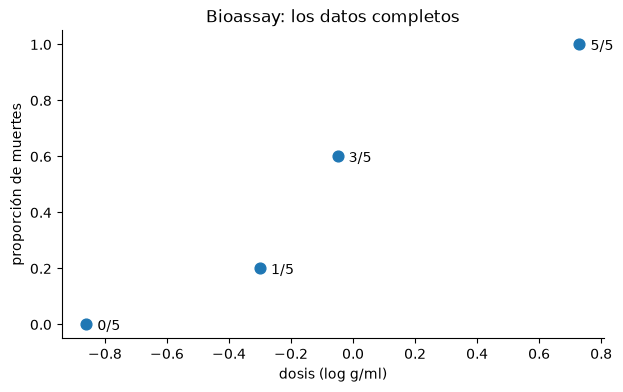

In [9]:
dosis = np.array([-0.86, -0.30, -0.05, 0.73])   # log(g/ml)
n_animales = np.array([5, 5, 5, 5])
muertes = np.array([0, 1, 3, 5])

fig, ax = plt.subplots()
ax.scatter(dosis, muertes / n_animales, s=60, color="C0", zorder=3)
for x, y_, n_ in zip(dosis, muertes, n_animales):
    ax.annotate(f"{y_}/{n_}", (x, y_ / n_), textcoords="offset points", xytext=(8, -4))
ax.set_xlabel("dosis (log g/ml)")
ax.set_ylabel("proporción de muertes")
ax.set_ylim(-0.05, 1.05)
ax.set_title("Bioassay: los datos completos")
plt.show()

## 1.2 Qué estamos modelando? La tolerancia de cada animal

Antes de escribir una sola línea de PyMC, conviene preguntarse de dónde podría venir una curva como esta. Una historia muy natural:

- Cada animal $j$ tiene una **tolerancia** $\tau_j$: la dosis (en escala log) a partir de la cual muere. No la observamos.
- Los animales son distintos entre sí, así que las tolerancias varían en la población según alguna distribución con centro $m$ y escala $s$.
- Un animal que recibe la dosis $x$ muere si $x \ge \tau_j$.

Entonces la probabilidad de que un animal muera con la dosis $x$ es la probabilidad de que su tolerancia esté por debajo de $x$:

$$
P(\text{muere}\mid x) = P(\tau \le x) = F\!\left(\frac{x-m}{s}\right),
$$

donde $F$ es la función de distribución acumulada de las tolerancias estandarizadas. Ahora, si las tolerancias siguen una distribución **logística**, $F$ es justamente la función logística, y

$$
P(\text{muere}\mid x) = \operatorname{logística}\!\left(\frac{x-m}{s}\right) = \operatorname{logística}(\alpha + \beta x),
\qquad \beta = \frac{1}{s},\quad \alpha = -\frac{m}{s}.
$$

**Esto es una regresión logística.** Y ahora los coeficientes tienen un significado físico:

- $\beta = 1/s$ mide qué tan **parecidos** son los animales entre sí. Si todos tuvieran casi la misma tolerancia ($s$ chica), la curva sería casi un escalón y $\beta$ sería enorme.
- La dosis donde la probabilidad vale $1/2$ es la **mediana de las tolerancias**: $\text{LD}_{50} = m = -\alpha/\beta$.

Si en lugar de logísticas suponemos tolerancias **normales**, $F$ es la acumulada normal $\Phi$ y obtenemos la **regresión probit**. La liga, entonces, no es un detalle técnico, sino que más bien es una afirmación sobre cómo se reparten las tolerancias en la población. Lo vamos a aprovechar en la sección 1.8.

> **Para pensar.** En el reto, ¿qué sería la "tolerancia" de una tienda si la "dosis" fuera el descuento que le ofrece el vendedor? (Volvemos a esto en la sección 1.9.)

## 1.3 Las tres preguntas

**1. Familia.** En cada dosis hay $n_i=5$ animales que, dada la dosis, mueren de manera independiente con la misma probabilidad $p_i$. El número de muertes es entonces **binomial**:
$$y_i \mid p_i \sim \operatorname{Binomial}(n_i, p_i).$$
Podríamos escribir 20 renglones con un 0 o un 1 por animal y usar Bernoulli; daría exactamente el mismo posterior. La versión binomial dice lo mismo con 4 renglones. Conviene notar que la binomial supone que los animales de un mismo grupo son intercambiables, y que no hay variación extra entre grupos (por ejemplo, un lote de compuesto mal preparado). Con 4 grupos no podemos revisar eso muy a fondo.

**2. Media y liga.** $\operatorname{logit}(p_i) = \alpha + \beta x_i$, por la historia de las tolerancias.

**3. Priors.** Para poder comparar con el libro, que usa priors planos, usamos normales muy anchas: $\alpha \sim N(0, 10^2)$ y $\beta \sim N(0, 20^2)$. Con estas dosis, que van de $-0.86$ a $0.73$, un $\beta$ de 20 todavía es físicamente posible (una población muy homogénea), así que no queremos descartarlo.

In [10]:
with pm.Model() as m_logit:
    # Pregunta 3: priors
    a = pm.Normal("a", mu=0, sigma=10)
    b = pm.Normal("b", mu=0, sigma=20)

    # Pregunta 2: predictor lineal y liga (guardamos p para no recalcularla)
    p = pm.Deterministic("p", pm.math.invlogit(a + b * dosis))

    # Pregunta 1: familia. `observed` convierte esta línea en la verosimilitud
    pm.Binomial("muertes", n=n_animales, p=p, observed=muertes)

    # La cantidad que de verdad nos interesa, como función de los parámetros
    pm.Deterministic("LD50", -a / b)

    idata_logit = pm.sample(2000, tune=1000, chains=4, target_accept=0.95,
                            random_seed=SEMILLA)

Initializing NUTS using jitter+adapt_diag...



You can find the C code in this temporary file: /var/folders/kr/zlpqlpw96cj2wmtlnvjrfzc40000gn/T/pytensor_compilation_error_8_4z0tta


CompileError: Compilation failed (return status=1):
/usr/bin/clang++ -dynamiclib -g -Wno-c++11-narrowing -fno-exceptions -fno-unwind-tables -fno-asynchronous-unwind-tables -DNPY_NO_DEPRECATED_API=NPY_1_7_API_VERSION -fPIC -undefined dynamic_lookup -ld64 -I/opt/homebrew/lib/python3.11/site-packages/numpy/_core/include -I/opt/homebrew/opt/python@3.11/Frameworks/Python.framework/Versions/3.11/include/python3.11 -I/opt/homebrew/lib/python3.11/site-packages/pytensor/link/c/c_code -L/opt/homebrew/opt/python@3.11/Frameworks/Python.framework/Versions/3.11/lib -fvisibility=hidden -o /Users/mirandaurbansolano/.pytensor/compiledir_macOS-27.0.1-arm64-arm-64bit-arm-3.11.14-64/lazylinker_ext/lazylinker_ext.so /Users/mirandaurbansolano/.pytensor/compiledir_macOS-27.0.1-arm64-arm-64bit-arm-3.11.14-64/lazylinker_ext/mod.cpp
ld: library 'd64' not found
clang++: error: linker command failed with exit code 1 (use -v to see invocation)


## 1.4 Converge?

Antes de interpretar cualquier número, revisamos el diagnóstico. `az.summary` reporta, para cada parámetro, la media y la desviación posterior, un intervalo de alta densidad del 94% (`hdi_3%`, `hdi_97%`), el tamaño efectivo de muestra (`ess_bulk`, `ess_tail`) y $\hat R$ (`r_hat`).

Lo que buscamos: $\hat R = 1.00$ en todo, tamaños efectivos de varios cientos o más, y ninguna divergencia reportada al muestrear.

In [ ]:
az.summary(idata_logit, var_names=["a", "b", "LD50"], round_to=3)

Deberían ver medias cercanas a $\alpha \approx 1.2$, $\beta \approx 10.6$ y $\text{LD}_{50} \approx -0.11$ (sus números pueden diferir en el segundo decimal por el azar del muestreo). Comparen con el estimador de máxima verosimilitud: $\hat\alpha = 0.85$, $\hat\beta = 7.75$.

Fíjense en lo **anchos** que son los intervalos de $\alpha$ y $\beta$: el de $\beta$ va de unos 3 a más de 20. Con 20 animales, eso era de esperarse. Lo sorprendente viene ahora.

## 1.5 La posterior conjunto: los datos saben más de lo que parece

Grafiquemos las muestras de $(\alpha, \beta)$ juntas.

In [ ]:
a_s = muestras(idata_logit, "a")
b_s = muestras(idata_logit, "b")

fig, ax = plt.subplots(figsize=(6, 4.5))
ax.scatter(a_s, b_s, s=3, alpha=0.15, color="C0")
bb = np.linspace(0, b_s.max(), 50)
ax.plot(0.11 * bb, bb, color="C3", lw=2, label=r"$\alpha = 0.11\,\beta$  (es decir, LD$_{50}=-0.11$)")
ax.set_xlabel(r"$\alpha$")
ax.set_ylabel(r"$\beta$")
ax.legend(loc="upper left")
ax.set_title("Muestras del posterior conjunto")
plt.show()

print(f"Correlación posterior entre a y b: {np.corrcoef(a_s, b_s)[0, 1]:.2f}")

La nube tiene forma de plátano, alineada con la recta roja. ¿Por qué?

Los datos dicen con bastante claridad **dónde** está la mitad de la curva: entre la dosis $-0.30$ (1 de 5 muertes) y la dosis $-0.05$ (3 de 5). Lo que dicen poco es **qué tan empinada** es, porque no hay ninguna dosis entre $-0.05$ y $0.73$. Una curva suave y una casi vertical son ambas compatibles con los datos, siempre y cuando crucen el 50% en el mismo lugar. Y cruzar el 50% en $x = -0.11$ obliga a que $\alpha + \beta(-0.11) = 0$, o sea $\alpha \approx 0.11\,\beta$.

La lección es general: **la incertidumbre de cada coeficiente por separado puede ser enorme mientras una función de ellos está muy bien determinada.** Mirar solo la tabla de coeficientes habría escondido esto.

## 1.6 La curva dosis-respuesta, con su incertidumbre

Con muestras, dibujar la curva es una línea de numpy: para cada muestra $(\alpha^{(s)}, \beta^{(s)})$ evaluamos la logística en una malla de dosis, y luego tomamos cuantiles columna por columna.

In [ ]:
x_malla = np.linspace(-1.5, 1.5, 200)
p_malla = expit(a_s[:, None] + b_s[:, None] * x_malla)        # (n_muestras, 200)
banda = np.percentile(p_malla, [2.5, 50, 97.5], axis=0)

fig, ax = plt.subplots()
ax.fill_between(x_malla, banda[0], banda[2], alpha=0.25, color="C0", label="95% del posterior")
ax.plot(x_malla, banda[1], color="C0", lw=2, label="mediana")
for s in range(0, len(a_s), 400):                               # unas cuantas curvas creíbles
    ax.plot(x_malla, p_malla[s], color="C0", lw=0.5, alpha=0.3)
ax.scatter(dosis, muertes / n_animales, color="k", zorder=3, label="datos")
ax.axhline(0.5, color="gray", ls=":")
ax.set_xlabel("dosis (log g/ml)")
ax.set_ylabel("P(muere)")
ax.legend(loc="upper left")
plt.show()

Las curvas delgadas son muestras individuales: cada una es una población de animales creíble dados los datos. Noten que **todas cruzan el 50% en una zona angosta**, y se separan mucho en las colas. Esa es la imagen visual del plátano de la sección anterior.

## 1.7 La cantidad de interés: $\text{LD}_{50}$

Ya la guardamos como `Deterministic`, pero hacerlo a mano con las muestras es igual de fácil y les conviene ver que es lo mismo:
$$\text{LD}_{50}^{(s)} = -\alpha^{(s)}/\beta^{(s)}.$$

Un detalle que BDA discute: la $\text{LD}_{50}$ solo tiene sentido si $\beta > 0$ (si la probabilidad de muerte **sube** con la dosis). Si $\beta < 0$, la curva baja y "la dosis que mata a la mitad" describe algo completamente distinto. Por eso primero revisamos $P(\beta > 0 \mid \text{datos})$.

In [ ]:
print(f"P(b > 0 | datos) = {np.mean(b_s > 0):.4f}")

ld50 = -a_s / b_s
print(np.allclose(ld50, muestras(idata_logit, "LD50")))   # lo mismo que el Deterministic

resumen(ld50, "LD50 (log g/ml)")
resumen(np.exp(ld50), "LD50 (g/ml)")

fig, ax = plt.subplots()
ax.hist(ld50, bins=80, density=True, color="C0", alpha=0.7)
ax.set_xlabel(r"LD$_{50}$ (log g/ml)")
ax.set_ylabel("densidad posterior")
ax.set_title(r"Posterior de LD$_{50}$")
plt.show()

Deberían obtener una mediana de unos $-0.11$ en escala log, con intervalo del 95% aproximadamente de $[-0.28, 0.12]$; en g/ml, unos $0.90$ con intervalo $[0.76, 1.13]$. Es el mismo resultado de la Figura 3.4 de BDA3.

Comparen: el intervalo de $\beta$ abarcaba casi un orden de magnitud, mientras que el de $\text{LD}_{50}$ es angosto. Y un detalle técnico que importa: $\text{LD}_{50}$ es un **cociente** de dos coeficientes. El método clásico para su intervalo (el método delta) necesita una aproximación de primer orden que aquí funcionaría mal, porque el posterior está lejos de ser normal. Con muestras, la cuenta es exacta salvo por el error de Monte Carlo.

> **Para pensar.** ¿Por qué esta incertidumbre sobre $\text{LD}_{50}$ es razonable con solo 20 animales? Piensen en qué dosis tienen resultados "intermedios" (ni 0 ni 5 muertes).

## 1.8 Chequeo predictivo posterior

Simulamos experimentos completos con las muestras del posterior y los comparamos con el real. Con solo cuatro grupos, este chequeo tiene poco poder para detectar problemas; lo hacemos para practicar la mecánica, que en la Parte 2 va a ser decisiva.

In [ ]:
with m_logit:
    pm.sample_posterior_predictive(idata_logit, extend_inplace=True, random_seed=SEMILLA)

y_rep = muestras(idata_logit, "muertes", grupo="posterior_predictive")   # (n_muestras, 4)

tabla = pd.DataFrame({
    "dosis": dosis,
    "muertes observadas": muertes,
    "mediana simulada": np.median(y_rep, axis=0),
    "P(y_rep = y_obs)": (y_rep == muertes).mean(axis=0).round(2),
    "P(y_rep <= y_obs)": (y_rep <= muertes).mean(axis=0).round(2),
})
tabla

En cada dosis, el valor observado es un valor típico de lo que el modelo simula. Nada sospechoso, aunque con 5 animales por grupo es difícil que algo lo fuera.

## 1.9 ¿Y si cambio la liga? Logit contra probit

En la sección 1.2 vimos que escoger la liga equivale a escoger la distribución de las tolerancias: logística para logit, normal para probit. Ajustemos el modelo probit y comparemos lo que dicen los dos. Solo cambia una línea.

In [ ]:
with pm.Model() as m_probit:
    a = pm.Normal("a", mu=0, sigma=10)
    b = pm.Normal("b", mu=0, sigma=20)
    p = pm.Deterministic("p", pm.math.invprobit(a + b * dosis))    # la única línea distinta
    pm.Binomial("muertes", n=n_animales, p=p, observed=muertes)
    idata_probit = pm.sample(2000, tune=1000, chains=4, target_accept=0.95,
                             random_seed=SEMILLA)

az.summary(idata_probit, var_names=["a", "b"], round_to=3)

Los coeficientes son distintos (el $\beta$ del probit anda por 6 y el del logit por 10), y eso es normal: una logística estándar tiene desviación estándar $\pi/\sqrt3 \approx 1.8$, así que los coeficientes logit suelen ser unas 1.6 a 1.8 veces los del probit. **Comparar coeficientes entre ligas no tiene sentido.** Lo que sí se puede comparar son cantidades con significado: las dosis letales.

La dosis que mata a una fracción $q$ de los animales cumple $g(q) = \alpha + \beta x$, así que
$$\text{LD}_{q} = \frac{g(q) - \alpha}{\beta}, \qquad g = \operatorname{logit} \text{ o } g = \Phi^{-1}.$$

In [ ]:
a_p = muestras(idata_probit, "a")
b_p = muestras(idata_probit, "b")

filas = []
for q in [0.001, 0.01, 0.10, 0.50, 0.90]:
    ld_logit = (logit(q) - a_s) / b_s
    ld_probit = (norm.ppf(q) - a_p) / b_p
    ql = np.percentile(ld_logit, [2.5, 50, 97.5])
    qp = np.percentile(ld_probit, [2.5, 50, 97.5])
    filas.append({"fracción que muere": q,
                  "logit: mediana": ql[1], "logit: 95%": f"[{ql[0]:.2f}, {ql[2]:.2f}]",
                  "probit: mediana": qp[1], "probit: 95%": f"[{qp[0]:.2f}, {qp[2]:.2f}]"})
pd.DataFrame(filas).round(2)

Lo que deberían ver (en escala log g/ml, aproximadamente):

| fracción que muere | logit | probit |
|---|---|---|
| 0.50 | $-0.11$ $[-0.28, 0.12]$ | $-0.12$ $[-0.28, 0.12]$ |
| 0.10 | $-0.34$ $[-0.78, -0.16]$ | $-0.34$ $[-0.78, -0.18]$ |
| 0.001 | $-0.82$ $[-2.17, -0.41]$ | $-0.66$ $[-1.66, -0.37]$ |

En el centro, las dos ligas dicen **lo mismo**. En la cola, la que importa para la seguridad, se separan: el límite inferior del intervalo de la dosis que mata a 1 de cada 1,000 es $e^{-2.17} \approx 0.11$ g/ml con logit y $e^{-1.66} \approx 0.19$ g/ml con probit, casi el doble.

¿Cuál está bien? **Los datos no lo pueden decidir**: con 20 animales y ninguna dosis cerca de la cola, ambas ligas reproducen igual de bien lo observado. La diferencia viene enteramente del supuesto sobre la forma de la distribución de tolerancias. Veamos esas dos distribuciones, con los valores medianos del posterior:

In [ ]:
t = np.linspace(-1.5, 1.5, 400)
m_l, s_l = np.median(-a_s / b_s), np.median(1 / b_s)
m_n, s_n = np.median(-a_p / b_p), np.median(1 / b_p)
dens_logistica = np.exp(-(t - m_l) / s_l) / (s_l * (1 + np.exp(-(t - m_l) / s_l)) ** 2)
dens_normal = norm.pdf(t, m_n, s_n)

fig, axs = plt.subplots(1, 2, figsize=(11, 4))
for ax, escala in zip(axs, ["linear", "log"]):
    ax.plot(t, dens_logistica, label="logística (liga logit)")
    ax.plot(t, dens_normal, label="normal (liga probit)")
    ax.set_yscale(escala)
    ax.set_xlabel("tolerancia (log g/ml)")
axs[0].set_title("Distribución de tolerancias implícita")
axs[1].set_title("La misma, en escala log: las colas")
axs[1].set_ylim(1e-4, 10)
axs[0].legend()
plt.show()

En escala lineal son casi idénticas. En escala logarítmica se ve la diferencia: la logística tiene colas más pesadas, y por eso asigna más animales muy sensibles, que mueren con dosis bajas.

**Moraleja.** En el centro de los datos, la liga casi no importa. En cuanto la pregunta exige **extrapolar** a las colas (seguridad, riesgos raros, clientes extremos), la liga se vuelve un supuesto con consecuencias, y hay que reportarlo como tal, idealmente mostrando ambos resultados.

## 1.10 Puente al reto: del laboratorio a la tiendita

Cambien "dosis" por "descuento" y "muerte" por "la tienda acepta el producto nuevo". Supongan que Arca hace una prueba: a grupos de 24 tiendas les ofrece un SKU nuevo con distintos niveles de descuento, y registra cuántas lo aceptan.

| descuento (%) | tiendas | aceptan |
|---|---|---|
| 0 | 24 | 3 |
| 5 | 24 | 6 |
| 10 | 24 | 10 |
| 15 | 24 | 15 |
| 20 | 24 | 19 |

Es **el mismo modelo**: cada tienda tiene un umbral de descuento a partir del cual acepta (su "tolerancia"), y la $\text{ED}_{50}$ (dosis efectiva 50) es el descuento al que la mitad de las tiendas aceptaría. Para un gerente comercial, esa cifra con su intervalo vale más que cualquier coeficiente.

Un cuidado, y es el más importante de toda esta parte: el bioassay funciona porque **el laboratorio asignó las dosis**. Ningún animal escogió su dosis. Si en lugar de un experimento usaran el historial de Arca, donde el vendedor decidió a qué tiendas darles descuento (seguramente a las que ya veía con ganas de comprar, o a las que nunca compran), la curva mezclaría el efecto del descuento con el criterio del vendedor. La regresión es la misma; la interpretación cambia por completo según cómo se generó la $x$.

In [ ]:
# Prueba tú: completen el modelo y estimen la ED50 del descuento.
descuento = np.array([0, 5, 10, 15, 20])
tiendas = np.array([24, 24, 24, 24, 24])
aceptan = np.array([3, 6, 10, 15, 19])

# Sugerencia: el descuento va de 0 a 20, así que un prior N(0, 1) para la pendiente por punto
# porcentual ya es generoso (un b de 1 llevaría la probabilidad de 0.5 a 0.99 en 5 puntos).
#
# with pm.Model() as m_descuento:
#     a = ...
#     b = ...
#     p = ...
#     pm.Binomial(...)
#     idata_descuento = pm.sample(...)
#
# Como referencia: la máxima verosimilitud da una ED50 de unos 12% de descuento.

## 1.11 Prueba tú (opcional)

1. **Una tercera liga.** Ajusten el modelo con liga *complementary log-log*, $p = 1 - \exp(-e^{\eta})$, que corresponde a una distribución de tolerancias asimétrica. En PyMC: `p = 1 - pm.math.exp(-pm.math.exp(a + b * dosis))`. ¿Qué pasa con la $\text{LD}_{50}$? ¿Y con la dosis que mata a 1 de cada 1,000?
2. **Quiten la dosis más alta** (la de 5 de 5 muertes). ¿Qué le pasa al posterior de $\beta$? ¿Y al de $\text{LD}_{50}$? Fíjense en **cuál extremo** de cada intervalo se mueve, y expliquen por qué ese y no el otro.
3. **Diseño de experimentos.** Si tuvieran presupuesto para 5 animales más, ¿a qué dosis los asignarían para aprender más sobre $\text{LD}_{50}$? ¿Y para aprender más sobre la dosis segura? Simulen ambas opciones.
4. **Reparametrización.** Escriban el modelo directamente en términos de $(\text{LD}_{50}, \beta)$, con $\operatorname{logit}(p_i) = \beta(x_i - \text{LD}_{50})$. ¿Cómo se ve ahora el posterior conjunto? ¿Por qué esta parametrización le facilita la vida a NUTS?


# Parte 2. Arca: ¿cero porque no hay demanda, o porque no hay producto?

## 2.1 Situación

Arca quiere empujar un energético de su portafolio en una zona. Tiene, para 600 tienditas, cuántas cajas de ese energético vendieron al consumidor (sell out) durante el periodo en que las observó, que va de 4 a 26 semanas según la tienda. Además sabe cuatro cosas de cada tienda:

| variable | qué es |
|---|---|
| `semanas` | semanas observadas (la **exposición**) |
| `tamano` | tamaño de la tienda, estandarizado (media 0, desviación 1) |
| `escuela` | 1 si hay una escuela o un gimnasio a menos de 200 m |
| `ruta_semanal` | 1 si la ruta de preventa la visita cada semana; 0 si cada quince días |
| `dist_cedis` | distancia al centro de distribución, **en decenas de km** (1.2 = 12 km) |

Un tercio de las tiendas vendió **cero** cajas en todo el periodo. El director comercial pregunta:

> ¿Dónde está la demanda que no estamos atendiendo, y de qué tamaño es?

Es la trampa 3 del documento del reto, con todas sus letras: **ausencia de venta no es lo mismo que ausencia de demanda**. Una tienda puede vender cero porque a sus clientes no les interesa el producto, o porque el producto **nunca estuvo en su anaquel** (la ruta no lo ofreció, no hubo espacio en el refrigerador, el pedido no llegó). Desde la base de datos, los dos ceros se ven idénticos.

Vamos a ver que este problema, que suena a "necesitamos un método especial de detección de huecos", se resuelve con **dos regresiones pegadas**.

## 2.2 Los datos (inventados, a propósito)

Los datos son simulados. Eso tiene una ventaja enorme para aprender: **conocemos la verdad**, así que al final podremos revisar si cada modelo la recupera. Con los datos reales del reto no tendrán ese lujo, y por eso conviene practicar aquí.

El proceso que genera los datos es este, y les recomiendo leerlo con calma, porque **es** el modelo que vamos a querer reconstruir:

1. Cada tienda tiene el producto disponible o no. La probabilidad depende de la ruta, de la distancia al CEDIS y del tamaño de la tienda (regresión logística).
2. Si lo tiene, vende cajas a una tasa por semana que depende del tamaño y de si hay una escuela cerca (regresión con liga log), multiplicada por un factor propio de cada tienda que no observamos (gente, ubicación exacta, el dueño). Ese factor es lo que produce sobredispersión.
3. Si no lo tiene, vende cero.

Noten dos cosas del proceso verdadero: la **ruta y la distancia no afectan la demanda**, solo la disponibilidad; y la escuela afecta la demanda, pero no la disponibilidad. El parámetro `confusion` lo usaremos al final; por ahora vale cero.

In [ ]:
def generar_datos(semilla=2026, N=600, confusion=0.0):
    rng = np.random.default_rng(semilla)
    semanas = rng.integers(4, 27, size=N)              # de 4 a 26 semanas observadas
    tamano = rng.normal(0, 1, size=N)
    escuela = rng.binomial(1, 0.3, size=N)
    ruta_semanal = rng.binomial(1, 0.6, size=N)
    dist_cedis = rng.gamma(2.0, 0.6, size=N)           # decenas de km; media 1.2

    # factor propio de cada tienda, con media 1 (no lo observamos)
    phi = 1.0
    multiplicador = rng.gamma(phi, 1 / phi, size=N)

    # Paso 1: ¿el producto está disponible?
    eta_disp = (1.2 + 1.5 * ruta_semanal - 0.8 * dist_cedis + 0.4 * tamano
                + confusion * np.log(multiplicador))
    disponible = rng.binomial(1, expit(eta_disp))

    # Paso 2: demanda por semana (cajas) si está disponible
    tasa = np.exp(np.log(0.5) + 0.5 * tamano + 0.6 * escuela)

    # Paso 3: lo que se observa
    cajas = np.where(disponible == 1, rng.poisson(semanas * tasa * multiplicador), 0)

    datos = pd.DataFrame({"semanas": semanas, "tamano": tamano.round(3), "escuela": escuela,
                          "ruta_semanal": ruta_semanal, "dist_cedis": dist_cedis.round(3),
                          "cajas": cajas})
    verdad = pd.DataFrame({"disponible": disponible,
                           "tasa_media": tasa,                       # cajas/semana esperadas
                           "tasa_propia": tasa * multiplicador})     # incluyendo su factor propio
    return datos, verdad


datos, verdad = generar_datos()
datos.head(8)

La tabla `verdad` la vamos a dejar guardada en un cajón hasta la sección 2.9. Un analista real solo tiene `datos`.

## 2.3 Mirar antes de modelar

In [ ]:
y = datos["cajas"].values
semanas = datos["semanas"].values

print(f"Tiendas: {len(datos)}")
print(f"Proporción de tiendas con cero cajas: {np.mean(y == 0):.2f}")
print(f"Media: {y.mean():.2f}   Varianza: {y.var():.1f}   Varianza / media: {y.var() / y.mean():.0f}")
print(f"Mediana: {np.median(y):.0f}   Máximo: {y.max()}")
print()
print(datos.groupby("ruta_semanal")["cajas"].agg(
    tiendas="size", media="mean", prop_ceros=lambda s: np.mean(s == 0)).round(2))

In [ ]:
fig, axs = plt.subplots(1, 2, figsize=(11, 3.8))
axs[0].hist(np.minimum(y, 60), bins=np.arange(0, 62, 2), color="C0", alpha=0.8)
axs[0].set_xlabel("cajas en el periodo (60 o más, juntas en la última barra)")
axs[0].set_ylabel("tiendas")
axs[0].set_title("Muchos ceros y una cola larga")

axs[1].scatter(datos["tamano"], y / semanas, s=10, alpha=0.5,
               c=datos["ruta_semanal"], cmap="coolwarm")
axs[1].set_xlabel("tamaño (estandarizado)")
axs[1].set_ylabel("cajas por semana")
axs[1].set_title("Rojo: ruta semanal. Azul: quincenal")
plt.show()

Tres observaciones que van a guiar todo lo que sigue:

1. **35% de ceros**, con una media de 8.6 cajas. Una Poisson con esa media casi nunca daría cero.
2. La **varianza es unas 36 veces la media**. Los conteos están muy sobredispersos.
3. Entre las tiendas de **ruta quincenal**, la mitad vende cero; entre las de ruta semanal, una de cada cuatro. ¿Significa que la visita semanal genera demanda? Guarden esa pregunta.

Construimos la matriz de predictores. Todos los modelos de esta parte usan los mismos cuatro, para que la comparación sea limpia.

In [ ]:
predictores = ["tamano", "escuela", "ruta_semanal", "dist_cedis"]
X = datos[predictores].values.astype(float)
coords = {"predictor": predictores}


def tabla_efectos(idata, var="b", nombres=predictores, titulo="exp(b)"):
    # Mediana e intervalo del 95% de exp(coeficiente): el factor multiplicativo
    B = np.exp(muestras(idata, var))
    q = np.percentile(B, [2.5, 50, 97.5], axis=0)
    return pd.DataFrame({f"{titulo}: mediana": q[1], "2.5%": q[0], "97.5%": q[2]},
                        index=nombres).round(2)


def chequeo(idata, yobs, estadistico, nombre, mascara=None):
    # Chequeo predictivo posterior de un estadístico T: compara T(datos) con T(datos simulados)
    yrep = muestras(idata, "cajas", grupo="posterior_predictive")
    if mascara is not None:
        yrep, yobs = yrep[:, mascara], yobs[mascara]
    t_rep = np.array([estadistico(fila) for fila in yrep])
    t_obs = estadistico(yobs)
    q = np.percentile(t_rep, [2.5, 50, 97.5])
    print(f"{nombre:>36s}   datos: {t_obs:8.3f}   modelo: {q[1]:8.3f} [{q[0]:8.3f}, {q[2]:8.3f}]"
          f"   P(T_rep >= T_obs) = {np.mean(t_rep >= t_obs):.2f}")


prop_ceros = lambda v: np.mean(v == 0)

## 2.4 Modelo A: Poisson con exposición

**1. Familia.** Conteos: Poisson.
**2. Media.** La tasa por semana depende de las $x$ con liga log, y la media del periodo es tasa por semanas:
$$\log \mathbb{E}[y_i] = \underbrace{\log(\text{semanas}_i)}_{\text{offset}} + a + \textstyle\sum_j b_j x_{ij}.$$
**3. Priors.** $a \sim N(0, 1.5^2)$: la tasa base por semana anda, holgadamente, entre 0.05 y 20 cajas. $b_j \sim N(0, 1)$: con predictores estandarizados o binarios, un factor multiplicativo entre $e^{-2}\approx 0.14$ y $e^{2}\approx 7.4$ ya es muy generoso.

En el código no escribimos el offset con logaritmo: multiplicamos la tasa por las semanas, que es lo mismo y se lee mejor.

In [ ]:
with pm.Model(coords=coords) as m_pois:
    a = pm.Normal("a", 0, 1.5)
    b = pm.Normal("b", 0, 1, dims="predictor")
    tasa = pm.math.exp(a + pm.math.dot(X, b))                 # cajas por semana
    pm.Poisson("cajas", mu=semanas * tasa, observed=y)        # exposición: semanas
    idata_pois = pm.sample(1000, tune=1000, chains=4, random_seed=SEMILLA,
                           idata_kwargs={"log_likelihood": True})
    pm.sample_posterior_predictive(idata_pois, extend_inplace=True, random_seed=SEMILLA)

tabla_efectos(idata_pois)

Todo parece clarísimo: intervalos angostos, y la ruta semanal multiplica las ventas por unos **1.36** $[1.28, 1.44]$. Antes de creerle, el chequeo de la sesión 2: **¿el modelo puede producir datos como los nuestros?**

In [ ]:
chequeo(idata_pois, y, prop_ceros, "proporción de ceros")
chequeo(idata_pois, y, np.var, "varianza")
chequeo(idata_pois, y, np.max, "máximo")

El modelo simula alrededor de **4% de ceros** contra 35% en los datos, y una varianza de unas 95 contra 308. Los datos reales no se parecen a ninguno de los conjuntos simulados ($P = 0$). Igual que con las cucarachas: la Poisson es **sobreconfiada**, y sus intervalos angostos son una ilusión. Descartado.

## 2.5 Modelo B: binomial negativa

La respuesta de libro a la sobredispersión: cada tienda tiene su propio multiplicador Gamma con media 1, y al integrarlo queda una binomial negativa,
$$y_i \sim \operatorname{BinNeg}(\mu_i, \phi), \qquad \operatorname{Var}(y_i) = \mu_i + \mu_i^2/\phi.$$
Mismo predictor lineal, mismo offset. Para $\phi$, un prior exponencial con media 2.

In [ ]:
with pm.Model(coords=coords) as m_nb:
    a = pm.Normal("a", 0, 1.5)
    b = pm.Normal("b", 0, 1, dims="predictor")
    phi = pm.Exponential("phi", 0.5)
    tasa = pm.math.exp(a + pm.math.dot(X, b))
    pm.NegativeBinomial("cajas", mu=semanas * tasa, alpha=phi, observed=y)
    idata_nb = pm.sample(1000, tune=1000, chains=4, random_seed=SEMILLA,
                         idata_kwargs={"log_likelihood": True})
    pm.sample_posterior_predictive(idata_nb, extend_inplace=True, random_seed=SEMILLA)

print(az.summary(idata_nb, var_names=["phi"], round_to=2))
tabla_efectos(idata_nb)

In [ ]:
chequeo(idata_nb, y, prop_ceros, "proporción de ceros")
chequeo(idata_nb, y, np.var, "varianza")
chequeo(idata_nb, y, np.max, "máximo")

Ahora sí: la proporción de ceros simulada anda en 32% $[27\%, 37\%]$, y los datos (35%) caen dentro. La varianza y el máximo también. Con lo que vimos en clase, uno se daría por satisfecho y reportaría:

> "Las tiendas con visita semanal venden **49% más** ($e^{b} \approx 1.49$, intervalo $[1.16, 1.92]$), y cada 10 km de distancia al CEDIS **reducen la demanda** 16%."

De ahí saldría una recomendación muy concreta: pasar tiendas a ruta semanal para "generar demanda".

> **Para pensar.** Antes de seguir: ¿qué podría estar mal? Recuerden cómo se generaron los datos. ¿Qué chequeo haría falta para descubrirlo con los datos solos, sin espiar la verdad?

## 2.6 El chequeo que sí importa

En la sesión 2 dijimos que la $T$ del chequeo se escoge según **la pregunta**. Nuestra pregunta es sobre los ceros y sobre la ruta. Entonces revisemos los ceros **por separado** en cada tipo de ruta.

In [ ]:
quincenal = datos["ruta_semanal"].values == 0
chequeo(idata_nb, y, prop_ceros, "ceros, ruta quincenal", mascara=quincenal)
chequeo(idata_nb, y, prop_ceros, "ceros, ruta semanal", mascara=~quincenal)

Aquí el modelo se cae. En las tiendas de ruta quincenal, **50%** venden cero, y la binomial negativa solo imagina alrededor de 34% $[28\%, 41\%]$. En las de ruta semanal se pasa un poco del otro lado.

¿Qué pasó? La binomial negativa tiene **un solo mecanismo** para producir ceros: tiendas con demanda baja. Para explicar que las tiendas quincenales tienen el doble de ceros, la única palanca que tiene es bajarles la demanda. Por eso el coeficiente de la ruta salió positivo. Y para explicar el exceso global de ceros, infla la dispersión: $\phi \approx 0.46$, mucho menor que el valor verdadero.

El chequeo global de ceros pasó porque los dos errores se compensan al promediar. **Un chequeo agregado puede ocultar un error que un chequeo por grupo revela.**

## 2.7 Modelo C: ceros inflados, o dos regresiones pegadas

Escribamos el modelo **siguiendo la historia** de cómo se genera un cero, en lugar de buscar una familia que se parezca a los datos:

$$
\begin{aligned}
d_i &\sim \operatorname{Bernoulli}(\pi_i), & \operatorname{logit}(\pi_i) &= c + \textstyle\sum_j d_j x_{ij} & &\text{(¿el producto está disponible?)}\\[2pt]
y_i \mid d_i = 1 &\sim \operatorname{BinNeg}(\text{semanas}_i\,\lambda_i,\ \phi), & \log \lambda_i &= a + \textstyle\sum_j b_j x_{ij} & &\text{(¿cuánto vende si lo tiene?)}\\[2pt]
y_i \mid d_i = 0 &= 0. & & & &
\end{aligned}
$$

La disponibilidad $d_i$ **no se observa**: si una tienda vendió 5 cajas, sabemos que $d_i = 1$; si vendió cero, puede ser cualquiera de las dos. Integrando $d_i$ (sumando sobre sus dos valores), la verosimilitud de cada tienda queda:

$$
P(y_i = 0) = (1 - \pi_i) + \pi_i \cdot \operatorname{BinNeg}(0 \mid \mu_i, \phi), \qquad
P(y_i = k) = \pi_i \cdot \operatorname{BinNeg}(k \mid \mu_i, \phi) \quad (k \geq 1).
$$

Eso es un **modelo de ceros inflados**: una regresión logística y una binomial negativa, cada una con sus propios coeficientes, que comparten los datos. PyMC lo trae hecho: `pm.ZeroInflatedNegativeBinomial`, donde el argumento `psi` es la probabilidad de estar en la parte binomial negativa, o sea, nuestra $\pi_i$.

Ponemos **los cuatro predictores en las dos partes**. No le estamos diciendo al modelo cuál afecta qué: que lo descubra.

> **Comparación con la sesión 2.** El modelo de dos partes (*hurdle*) del ingreso suponía que todos los ceros venían de la parte logística. Aquí, en cambio, una tienda con el producto también puede vender cero por azar (una tienda chiquita, observada 4 semanas). Por eso este es de ceros inflados y no de dos partes.

Lo escribimos como función, porque lo vamos a volver a usar al final.

In [ ]:
def ajustar_zinb(datos, semilla=SEMILLA):
    X_ = datos[predictores].values.astype(float)
    semanas_ = datos["semanas"].values
    y_ = datos["cajas"].values
    with pm.Model(coords=coords) as modelo:
        # Parte 1: ¿el producto está disponible? (logística)
        c = pm.Normal("c", 0, 1.5)
        d = pm.Normal("d", 0, 1, dims="predictor")
        p_disp = pm.Deterministic("p_disp", pm.math.invlogit(c + pm.math.dot(X_, d)))

        # Parte 2: ¿cuánto vende si lo tiene? (binomial negativa con liga log)
        a = pm.Normal("a", 0, 1.5)
        b = pm.Normal("b", 0, 1, dims="predictor")
        phi = pm.Exponential("phi", 0.5)
        tasa = pm.Deterministic("tasa", pm.math.exp(a + pm.math.dot(X_, b)))   # cajas/semana

        # Las dos partes, pegadas
        pm.ZeroInflatedNegativeBinomial("cajas", psi=p_disp, mu=semanas_ * tasa, alpha=phi,
                                        observed=y_)
        idata = pm.sample(1000, tune=1000, chains=4, random_seed=semilla,
                          idata_kwargs={"log_likelihood": True})
        pm.sample_posterior_predictive(idata, extend_inplace=True, random_seed=semilla)
    return modelo, idata


m_zinb, idata_zinb = ajustar_zinb(datos)
az.summary(idata_zinb, var_names=["a", "b", "phi", "c", "d"], round_to=2)

In [ ]:
print("Parte de DEMANDA: factor multiplicativo sobre las cajas por semana")
display(tabla_efectos(idata_zinb, "b"))
print("\nParte de DISPONIBILIDAD: factor multiplicativo sobre los momios de tener el producto")
display(tabla_efectos(idata_zinb, "d", titulo="exp(d)"))

Lean las dos tablas con calma. Deberían ver algo así:

| | demanda, $e^{b}$ | disponibilidad, $e^{d}$ (momios) |
|---|---|---|
| tamaño (+1 d.e.) | 1.59 | 1.55 |
| escuela cerca | 1.97 | 1.17 $[0.71, 1.95]$ |
| ruta semanal | **0.99** $[0.79, 1.25]$ | **5.3** $[3.2, 9.3]$ |
| +10 km al CEDIS | **1.00** $[0.88, 1.14]$ | **0.50** $[0.37, 0.66]$ |

El modelo separó los mecanismos solito: la ruta y la distancia **no tienen nada que ver con la demanda**, y en cambio multiplican (o dividen) los momios de que el producto esté en la tienda. La escuela mueve la demanda y no la disponibilidad. Y $\phi$ sube a alrededor de 1: ya no tiene que inflar la dispersión para fabricar ceros.

Es la narrativa "No les falta demanda, les falta reparto" del documento del reto, salida directamente de una regresión.

In [ ]:
for nombre_t, masc in [("ceros, todas", None), ("ceros, ruta quincenal", quincenal),
                        ("ceros, ruta semanal", ~quincenal)]:
    chequeo(idata_zinb, y, prop_ceros, nombre_t, mascara=masc)
chequeo(idata_zinb, y, np.var, "varianza")
chequeo(idata_zinb, y, np.max, "máximo")

Ahora los ceros por tipo de ruta también salen bien: alrededor de 50% en las quincenales y 27% en las semanales.

## 2.8 La misma pregunta, tres respuestas

¿Cuál es el efecto de la ruta semanal? Pongamos lado a lado lo que dijo cada modelo.

In [ ]:
def intervalo(v):
    return np.percentile(v, [2.5, 50, 97.5])

j = predictores.index("ruta_semanal")
filas = [
    ("Poisson: demanda", intervalo(np.exp(muestras(idata_pois, "b")[:, j]))),
    ("Bin. negativa: demanda", intervalo(np.exp(muestras(idata_nb, "b")[:, j]))),
    ("Ceros inflados: demanda", intervalo(np.exp(muestras(idata_zinb, "b")[:, j]))),
    ("Ceros inflados: disponibilidad (momios)", intervalo(np.exp(muestras(idata_zinb, "d")[:, j]))),
]
verdad_ruta = [1.0, 1.0, 1.0, np.exp(1.5)]

fig, ax = plt.subplots(figsize=(8, 3.2))
for k, ((nombre_f, q), v) in enumerate(zip(filas, verdad_ruta)):
    ax.plot([q[0], q[2]], [k, k], lw=4, color="C0" if k < 3 else "C1")
    ax.plot(q[1], k, "o", color="k")
    ax.plot(v, k, "x", color="C3", ms=10, mew=2)
ax.set_yticks(range(len(filas)), [f[0] for f in filas])
ax.axvline(1, color="gray", ls=":")
ax.set_xscale("log")
ax.set_xticks([0.5, 1, 2, 5, 10], ["0.5", "1", "2", "5", "10"])
ax.set_xlabel("factor multiplicativo (escala log)   |   x roja: valor verdadero")
ax.invert_yaxis()
plt.show()

- La **Poisson** encuentra un efecto de la ruta sobre la demanda, con un intervalo angostísimo. Falso y sobreconfiado.
- La **binomial negativa** encuentra el mismo efecto falso, con un intervalo más honesto en anchura, pero centrado en el lugar equivocado. Mejor modelo de los datos; **misma conclusión equivocada**.
- La de **ceros inflados** pone el efecto donde está: en la disponibilidad.

Este es el punto central de toda la parte: **un modelo mal especificado no solo da intervalos malos, puede inventar efectos.** Y la recomendación de negocio cambia por completo. Con el modelo B, "pasemos tiendas a ruta semanal para generar demanda". Con el modelo C, "la demanda ya está ahí; lo que falta es que el producto llegue".

## 2.9 ¿Recuperó la verdad?

Abramos el cajón. Esto solo se puede hacer con datos simulados, y es la razón principal para simular: **un modelo que no recupera los parámetros con datos que salieron de él mismo no merece confianza con datos reales.** A esto Gelman y coautores le llaman *fake-data simulation*, y es parte del flujo de trabajo bayesiano.

In [ ]:
verdaderos = {
    "a (log tasa base)": (np.log(0.5), muestras(idata_zinb, "a")),
    "phi": (1.0, muestras(idata_zinb, "phi")),
    "c (logit disp. base)": (1.2, muestras(idata_zinb, "c")),
}
for nombre_p, valor in zip(predictores, [0.5, 0.6, 0.0, 0.0]):
    verdaderos[f"b[{nombre_p}]"] = (valor, muestras(idata_zinb, "b")[:, predictores.index(nombre_p)])
for nombre_p, valor in zip(predictores, [0.4, 0.0, 1.5, -0.8]):
    verdaderos[f"d[{nombre_p}]"] = (valor, muestras(idata_zinb, "d")[:, predictores.index(nombre_p)])

filas = []
for nombre_p, (valor, s) in verdaderos.items():
    q = np.percentile(s, [2.5, 50, 97.5])
    filas.append({"parámetro": nombre_p, "verdadero": valor, "mediana": q[1],
                  "2.5%": q[0], "97.5%": q[2], "¿dentro?": q[0] <= valor <= q[2]})
pd.DataFrame(filas).round(2)

Todos los valores verdaderos deberían caer dentro de su intervalo del 95%. (Si uno quedara fuera no sería escandaloso: con 13 parámetros, esperaríamos que de vez en cuando alguno se salga. Lo preocupante sería un patrón sistemático.)

## 2.10 Comparar con validación cruzada

`az.compare` calcula $\text{elpd}_{\text{loo}}$ con PSIS-LOO para cada modelo y los ordena. Como vimos en clase, una diferencia se toma en serio si es varias veces su error estándar (`dse`).

In [ ]:
comparacion = az.compare({"Poisson": idata_pois,
                          "binomial negativa": idata_nb,
                          "ceros inflados": idata_zinb})
comparacion

El modelo de ceros inflados queda arriba por unos 40 puntos sobre la binomial negativa, con un error estándar de la diferencia de alrededor de 9: más de cuatro errores estándar. La Poisson queda a miles de puntos, y ArviZ probablemente les advierta que varios datos tienen $\hat k$ alto para ella: es la misma señal de la sesión 2, el modelo está muy sorprendido por esos datos.

Noten el orden de los argumentos: llegamos al modelo C **por el chequeo por grupo**, que nos dijo qué estaba mal y cómo arreglarlo. LOO confirma, pero por sí solo no nos habría dicho por qué la binomial negativa fallaba.

## 2.11 De coeficientes a una lista para el lunes

Al director comercial no le sirve $e^{d} = 5.3$. Le sirve saber **en qué tiendas** hay demanda sin atender, **cuánta**, y **con qué confianza**. Con el posterior, esas preguntas son unas cuantas líneas de numpy.

**Paso 1. Para cada tienda con cero ventas, ¿qué tan probable es que el producto no estuviera?** Por la regla de Bayes, con cada muestra del posterior:

$$
P(\text{sin producto} \mid y_i = 0) = \frac{1 - \pi_i}{(1 - \pi_i) + \pi_i \cdot \operatorname{BinNeg}(0 \mid \mu_i, \phi)},
\qquad \operatorname{BinNeg}(0 \mid \mu, \phi) = \left(\frac{\phi}{\phi + \mu}\right)^{\phi}.
$$

**Paso 2. Si se lo surtiéramos, ¿cuánto vendería?** Su tasa $\lambda_i$, que el modelo aprendió de las tiendas parecidas que sí lo tienen.

**Paso 3. Valor esperado** de surtir la tienda $i$, en cajas por mes: $P(\text{sin producto} \mid y_i = 0) \cdot \lambda_i \cdot 4.33$.

In [ ]:
SEMANAS_POR_MES = 4.33


def calcular_oportunidad(idata, datos):
    semanas_ = datos["semanas"].values
    cero = datos["cajas"].values == 0
    tasa_s = muestras(idata, "tasa")                     # (n_muestras, N): cajas/semana si lo tiene
    pdisp_s = muestras(idata, "p_disp")                  # (n_muestras, N)
    phi_s = muestras(idata, "phi")[:, None]
    p0_nb = (phi_s / (phi_s + semanas_ * tasa_s)) ** phi_s
    p_sin = (1 - pdisp_s) / ((1 - pdisp_s) + pdisp_s * p0_nb)
    valor = p_sin * tasa_s * SEMANAS_POR_MES             # cajas/mes esperadas al surtir
    total = valor[:, cero].sum(axis=1)                   # una cifra por muestra del posterior
    return p_sin, tasa_s, valor, total, cero


p_sin, tasa_s, valor, total, cero = calcular_oportunidad(idata_zinb, datos)

print(f"Tiendas con cero ventas: {cero.sum()}")
resumen(total, "oportunidad total (cajas/mes)")

Comparemos con lo que habría dicho un análisis ingenuo, que supone que **todas** las tiendas en cero venderían como el promedio de las que sí venden. Y, como podemos, con la verdad.

In [ ]:
vende = ~cero
tasa_promedio = np.mean(y[vende] / semanas[vende])
ingenuo = cero.sum() * tasa_promedio * SEMANAS_POR_MES
real = verdad.loc[verdad["disponible"] == 0, "tasa_media"].sum() * SEMANAS_POR_MES

print(f"Ingenuo (toda tienda en cero = tienda promedio): {ingenuo:7.0f} cajas/mes")
q = np.percentile(total, [2.5, 50, 97.5])
print(f"Modelo de ceros inflados:                        {q[1]:7.0f} cajas/mes   [{q[0]:.0f}, {q[2]:.0f}]")
print(f"Verdad (solo posible con datos simulados):       {real:7.0f} cajas/mes")

Deberían ver algo como 800 cajas al mes para el cálculo ingenuo, unas 460 $[360, 560]$ con el modelo, y una verdad de unas 455. Es "el potencial que se encogió" del documento del reto: el ingenuo se equivoca dos veces, porque cuenta como oportunidad las tiendas que **sí tenían** el producto y no lo vendieron (unas 50 de las 210), y porque supone que las tiendas sin producto son como el promedio, cuando tienden a ser más chicas.

Ahora la lista corta: las diez tiendas con mayor valor esperado.

In [ ]:
lista = datos.copy()
lista["P(sin producto | 0)"] = p_sin.mean(axis=0)
lista["cajas/mes si se surte"] = np.median(tasa_s, axis=0) * SEMANAS_POR_MES
lista["valor esperado (cajas/mes)"] = valor.mean(axis=0)
lista = lista[cero].sort_values("valor esperado (cajas/mes)", ascending=False)

top10 = lista.head(10)
top10[["tamano", "escuela", "ruta_semanal", "dist_cedis",
       "P(sin producto | 0)", "cajas/mes si se surte", "valor esperado (cajas/mes)"]].round(2)

Esta tabla ya habla el idioma del socio: "estas diez tiendas, casi seguro, no tienen el producto; si lo tuvieran, venderían entre 6 y 17 cajas al mes cada una". Noten el perfil: tiendas grandes, casi todas con escuela cerca, y lejos del CEDIS o con ruta quincenal.

Y, como podemos, revisemos contra la verdad: ¿cuántas de esas diez de verdad no tenían el producto?

In [ ]:
print("De las 10 primeras, sin producto en realidad:", int((1 - verdad.loc[top10.index, "disponible"]).sum()))
top30 = lista.head(30).index
print("De las 30 primeras, sin producto en realidad:", int((1 - verdad.loc[top30, "disponible"]).sum()))

# ¿Qué tan bien separa el modelo los dos tipos de cero, tienda por tienda?
p_cero = lista["P(sin producto | 0)"].values
sin_real = 1 - verdad.loc[lista.index, "disponible"].values
cortes = [0, 0.5, 0.7, 0.85, 0.95, 1.0]
grupo = pd.cut(p_cero, cortes, include_lowest=True)
pd.DataFrame({"P predicha": p_cero, "sin producto (verdad)": sin_real}).groupby(
    grupo, observed=True).agg(tiendas=("P predicha", "size"),
                              P_predicha=("P predicha", "mean"),
                              proporcion_real=("sin producto (verdad)", "mean")).round(2)

La lista corta es muy confiable: deberían ver 10 de 10, y unas 29 de 30. La tabla de abajo es una **calibración** como la de los pozos de Bangladesh: en cada grupo, la probabilidad predicha y la proporción real deberían parecerse, y se parecen razonablemente.

Pero noten algo honesto: entre las tiendas con probabilidad intermedia (0.5 a 0.85), el modelo **no puede saber** de cuál tipo es cada una. Una tienda chica observada pocas semanas que vendió cero es genuinamente ambigua. El modelo es muy bueno para el **total** y para la **parte alta de la lista**, y modesto para cada tienda individual. Eso es exactamente lo que hay que comunicar.

## 2.12 Lo que el modelo no puede saber

Todo lo anterior salió bien porque, en nuestro mundo inventado, **la disponibilidad no dependía de la demanda propia de cada tienda**, una vez que conocemos tamaño, escuela, ruta y distancia. Esa es una suposición fuerte. En la vida real, el vendedor conoce a sus tiendas: deja de ofrecerle el energético a la que nunca lo mueve, y se esfuerza con la que sí. Entonces las tiendas sin producto tenderían a ser, además, tiendas con menos demanda de la que sus características sugieren.

Simulemos ese mundo. El parámetro `confusion=1.0` hace que la probabilidad de tener el producto suba con el factor propio de la tienda, ese que no observamos. Todo lo demás queda igual. Ajustamos **exactamente el mismo modelo**.

In [ ]:
datos_conf, verdad_conf = generar_datos(confusion=1.0)
m_conf, idata_conf = ajustar_zinb(datos_conf)

y_conf = datos_conf["cajas"].values
quincenal_conf = datos_conf["ruta_semanal"].values == 0
chequeo(idata_conf, y_conf, prop_ceros, "ceros, todas")
chequeo(idata_conf, y_conf, prop_ceros, "ceros, ruta quincenal", mascara=quincenal_conf)
chequeo(idata_conf, y_conf, prop_ceros, "ceros, ruta semanal", mascara=~quincenal_conf)
chequeo(idata_conf, y_conf, np.var, "varianza")
chequeo(idata_conf, y_conf, np.max, "máximo")

Todos los chequeos pasan. El modelo se ve impecable. Ahora la oportunidad:

In [ ]:
_, _, _, total_conf, _ = calcular_oportunidad(idata_conf, datos_conf)
sin_producto = verdad_conf["disponible"] == 0
real_conf = verdad_conf.loc[sin_producto, "tasa_propia"].sum() * SEMANAS_POR_MES

q = np.percentile(total_conf, [2.5, 50, 97.5])
print(f"Modelo de ceros inflados: {q[1]:5.0f} cajas/mes   [{q[0]:.0f}, {q[2]:.0f}]")
print(f"Verdad:                   {real_conf:5.0f} cajas/mes")

Deberían ver una estimación de unas 770 cajas al mes, con un intervalo de aproximadamente $[660, 890]$, contra una verdad de unas **310**. El modelo **sobreestima la oportunidad dos veces y media**, con un intervalo que ni siquiera se acerca al valor real, y **ningún chequeo con estos datos podía avisarnos**.

¿Por qué? El modelo aprende la demanda de las tiendas que tienen el producto y supone que las que no lo tienen se comportarían igual, condicionando en las $x$. Cuando la disponibilidad depende de algo que no medimos y que también mueve la demanda, esa suposición se rompe. Es un problema de **confusión** (lo veremos con toda formalidad en la parte de inferencia causal), y es la trampa 5 del reto: **estimar el beneficio con la política que lo generó**.

Qué se puede hacer, en orden de preferencia:

1. **Un piloto aleatorizado.** Escoger al azar 40 de las tiendas de la lista, surtirles el producto, y medir. El azar rompe la conexión entre "tener el producto" y "lo que el vendedor sabe". Es la misma razón por la que el bioassay funciona: el laboratorio asignó las dosis.
2. **Medir lo que el vendedor sabe.** Si la razón por la que no se surte está en algún registro (rechazos previos, notas de visita), meterla al modelo.
3. **Reportar con honestidad.** Decir explícitamente que la cifra supone que las tiendas sin producto son comparables a las que sí lo tienen, y que si no lo son, la cifra está inflada. Presentarla como cota superior, o con un análisis de sensibilidad.

> **Para pensar.** El documento del reto dice que un rango amplio pero bien argumentado vale más que un número puntual sin respaldo. ¿Qué rango le darían a Arca, sabiendo esto? ¿Cómo justificarían el límite inferior?

## 2.13 ¿Y si Arca sí ve la disponibilidad?

Aquí una pregunta de "primera traducción" del reto, antes de cualquier modelo: **¿es realmente latente la disponibilidad?** Arca conoce su sell in. Si una tienda nunca le compró el energético a Arca, sabemos que no lo tuvo (salvo que lo consiga por otro lado). Si le compró, sabemos que lo tuvo, al menos un rato.

Cuando la disponibilidad se observa, el modelo se simplifica: ya no hace falta la mezcla, y quedan **dos regresiones separadas**:

1. una **logística** para "¿la tienda tiene el producto?", con todas las tiendas;
2. una **binomial negativa con offset** para "¿cuánto vende?", solo con las tiendas que lo tienen.

Es el modelo de dos partes de la sesión 2, con la valla observada. Moraleja: antes de construir un modelo con una variable latente, pregúntense si esa variable está en alguna otra tabla. Cruzar el sell out con el sell in puede valer más que el mejor modelo de mezclas. Y aun así, la sección 2.12 sigue aplicando: saber quién tiene el producto no dice por qué lo tiene.

## 2.14 Prueba tú (opcional)

1. **Disponibilidad observada.** Usen `verdad["disponible"]` como si fuera el dato de sell in, y ajusten las dos regresiones separadas de la sección 2.13. ¿Se parecen los coeficientes a los del modelo de ceros inflados? ¿Cuánto se angostan los intervalos de la parte de disponibilidad? ¿Por qué?
2. **Ceros inflados con Poisson.** Cambien `pm.ZeroInflatedNegativeBinomial` por `pm.ZeroInflatedPoisson` (sin `alpha`). ¿Pasa el chequeo de la varianza? ¿Qué le pasa al coeficiente de la ruta en la parte de demanda?
3. **Menos información.** Repitan el análisis con `N=150` tiendas en `generar_datos`. ¿Sigue el modelo separando la ruta de la demanda? ¿Qué pasa con la lista corta?
4. **Grados de confusión.** Prueben `confusion=0.5` y `confusion=2.0`. Grafiquen la oportunidad estimada contra la verdadera. ¿Qué tan rápido se degrada?
5. **Un predictor con efecto en las dos partes.** Modifiquen el generador para que `escuela` también aumente la disponibilidad. ¿Puede el modelo separar los dos efectos?


# Cierre: lo que parecía complejo y salió con regresión

| El problema, como suena | Lo que en realidad era |
|---|---|
| "¿Qué dosis es letal para la mitad de la población?" | Regresión binomial con liga logit, y luego **un cociente de coeficientes**, $-\alpha/\beta$, calculado muestra por muestra |
| "¿Qué dosis es segura?" | La misma regresión, extrapolada a la cola, donde **la liga es un supuesto** que los datos no pueden verificar |
| "¿Qué descuento hace que la mitad de las tiendas acepte?" | El bioassay con otros nombres, siempre que el descuento lo haya asignado un experimento |
| "¿Qué tiendas tienen un hueco de distribución?" | Una **regresión logística latente** pegada a una **binomial negativa con offset**, más la regla de Bayes para cada tienda en cero |
| "¿De qué tamaño es la oportunidad?" | Una suma sobre tiendas de una función del posterior, con su intervalo, y con un supuesto causal que hay que declarar |

Y tres lecciones que valen para el dataset real del reto:

1. **Escriban el modelo siguiendo la historia** de cómo se generan los datos (tolerancias, disponibilidad, demanda), en lugar de buscar la familia que mejor se ajuste. Los coeficientes de un modelo así significan algo.
2. **El chequeo predictivo se diseña según la pregunta.** El chequeo global de ceros dejó pasar un modelo que inventaba un efecto; el chequeo por tipo de ruta lo tumbó.
3. **Un modelo que pasa todos los chequeos todavía puede responder mal una pregunta contrafactual.** Los datos les dicen a quién se le surtió, casi nunca qué habría pasado con quien quedó fuera.

### Ideas para el reto

- Si su sell out viene por tienda y semana, piensen en **semanas con producto** como exposición, y en la mezcla de ceros (estructurales contra de azar) como la versión formal de "ausencia de venta no es ausencia de demanda".
- Si tienen sell in y sell out, **crucen las dos fuentes** antes de modelar: muchas latentes dejan de serlo.
- Si estiman una oportunidad, reporten el total con intervalo, la lista corta con su probabilidad, y el supuesto que la volvería optimista. Esa es la frase que se califica.